# Medical-device sales: churn prediction and revenue forecasting

Two planning questions for a B2B medical-device business, answered on synthetic data from `generate_data.py`:

1. **Churn:** which accounts are most likely to be lost in the next 90 days?
2. **Revenue:** what will monthly revenue be over the next six months, and how confident should we be?

The logic lives in `churn_model.py`, `revenue_forecast.py` and `analysis.py`; this notebook runs it and shows the results.

In [1]:
import json

import pandas as pd
from IPython.display import Image, display

from analysis import run_analysis

pd.set_option("display.precision", 3)
summary = run_analysis()
churn, revenue = summary["churn"], summary["revenue"]
pd.Series(churn["split"])

train_rows                                                     750
validation_rows                                                280
test_rows                                                      280
train_snapshots         [2021-01-01 00:00:00, 2023-01-20 00:00:00]
validation_snapshots    [2023-04-21 00:00:00, 2024-01-25 00:00:00]
test_snapshots          [2024-01-26 00:00:00, 2024-10-31 00:00:00]
label_embargo_days                                              90
test_churn_rate                                              0.225
dtype: object

## Churn: model selection on the validation period

Snapshots are split chronologically (60/20/20). Training rows whose 90-day outcome window is still open when validation starts are dropped, so the model only learns from labels that would have been observed. Candidates are compared on validation log loss, which rewards calibrated probabilities as well as ranking.

In [2]:
pd.read_csv("metrics/churn_model_selection.csv")

,model,params,roc_auc,pr_auc,brier,log_loss
0,logistic_regression,"{""C"": 0.01}",0.851,0.705,0.137,0.432
1,logistic_regression,"{""C"": 0.1}",0.850,0.695,0.127,0.401
2,logistic_regression,"{""C"": 1.0}",0.846,0.683,0.130,0.404
3,logistic_regression,"{""C"": 10.0}",0.845,0.680,0.131,0.405
4,gradient_boosting,"{""learning_rate"": 0.05, ""max_iter"": 100, ""max_...",0.822,0.630,0.141,0.435
5,gradient_boosting,"{""learning_rate"": 0.05, ""max_iter"": 200, ""max_...",0.811,0.614,0.147,0.455
6,gradient_boosting,"{""learning_rate"": 0.03, ""max_iter"": 300, ""max_...",0.830,0.658,0.136,0.421
7,gradient_boosting,"{""learning_rate"": 0.1, ""max_iter"": 100, ""max_l...",0.801,0.598,0.162,0.522


## Churn: test-period performance

Because the data are synthetic, the generator's true churn probability is known. Its score on the test period is the best any model could achieve on these rows.

In [3]:
ci = churn["uncertainty_95pct"]
rows = []
for name, m in churn["test"].items():
    row = {"model": name, **m}
    if name in ci:
        row["roc_auc_95ci"] = f"{ci[name]['roc_auc']['low_2.5']:.3f} to {ci[name]['roc_auc']['high_97.5']:.3f}"
    if name in churn["top_decile"]:
        row["top_decile_precision"] = churn["top_decile"][name]["precision"]
    rows.append(row)
display(pd.DataFrame(rows).set_index("model"))
diff = ci["roc_auc_difference_logistic_regression_minus_gradient_boosting"]
print(f"Paired ROC-AUC difference, logistic minus boosting: {diff['low_2.5']:.3f} to {diff['high_97.5']:.3f} (95% CI)")

,roc_auc,pr_auc,brier,log_loss,roc_auc_95ci,top_decile_precision
model,,,,,,
prevalence_baseline,0.500,0.225,0.174,0.533,NaN,NaN
logistic_regression,0.790,0.577,0.136,0.426,0.723 to 0.851,0.643
gradient_boosting,0.730,0.483,0.156,0.481,0.657 to 0.799,0.500
oracle_true_probability,0.792,0.579,0.136,0.424,NaN,0.643


Paired ROC-AUC difference, logistic minus boosting: 0.026 to 0.096 (95% CI)


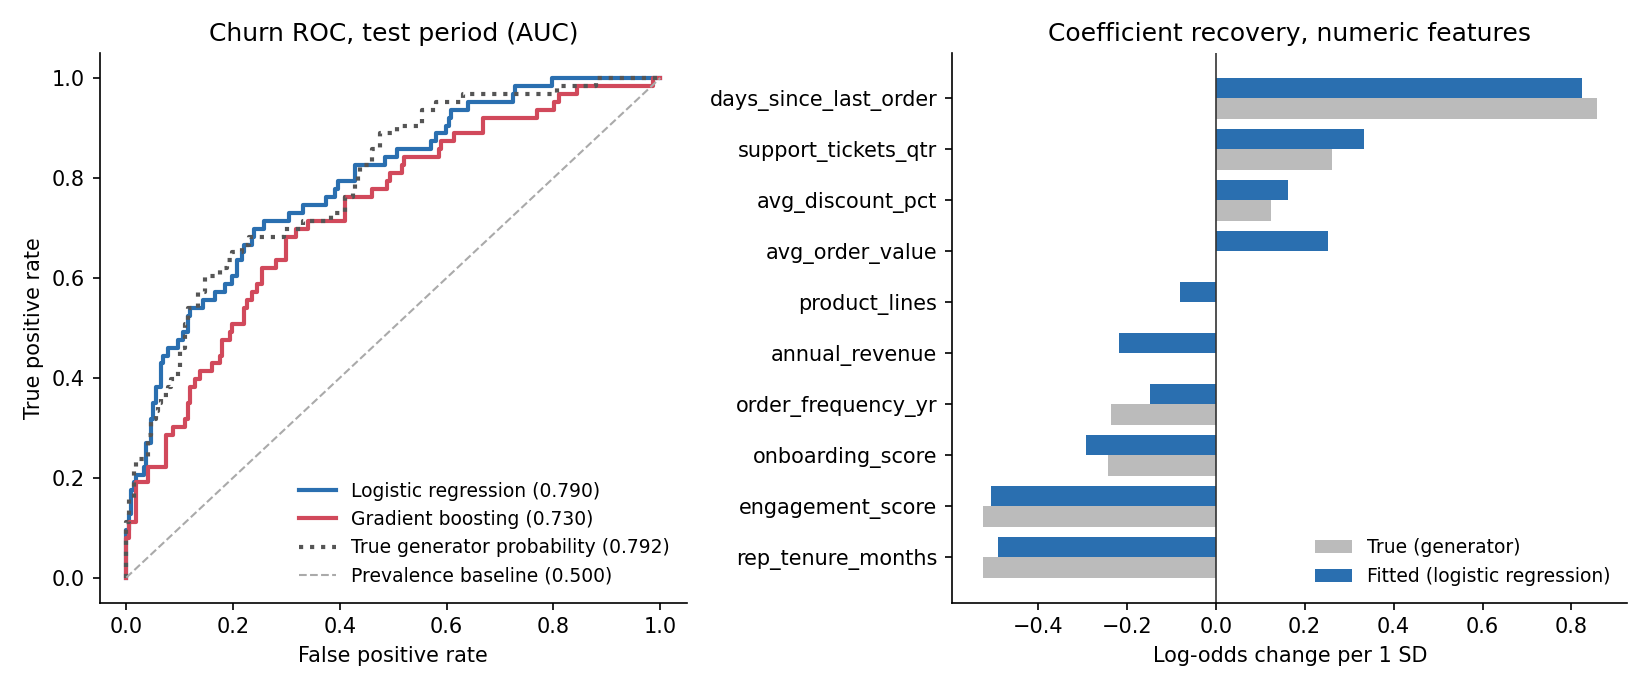

,bin,mean_predicted,observed_rate,model
0,1,0.036,0.018,logistic_regression
1,2,0.084,0.143,logistic_regression
2,3,0.164,0.143,logistic_regression
3,4,0.272,0.268,logistic_regression
4,5,0.575,0.554,logistic_regression
5,1,0.045,0.089,gradient_boosting
6,2,0.085,0.089,gradient_boosting
7,3,0.139,0.179,gradient_boosting
8,4,0.255,0.304,gradient_boosting
9,5,0.568,0.464,gradient_boosting


In [4]:
display(Image("figures/roc_curves.png"))
pd.read_csv("metrics/churn_calibration.csv")

Logistic regression essentially matches the true probability on this test period, and gradient boosting trails it. That is the expected result when the true relationship is linear in the log-odds: the extra flexibility of trees only adds variance. All seven true churn drivers are recovered with the correct sign.

In [5]:
pd.Series(churn["coefficient_recovery"])

true_drivers                      7.000
true_drivers_with_correct_sign    7.000
correlation_fitted_vs_true        0.881
dtype: float64

## Retention value at different outreach capacities

**Assumptions (stated, not estimated):** outreach retains 30% of accounts that would otherwise churn and costs $2,500 per account contacted. Revenue protected is the save rate times the annual revenue (from the data) of churners on the list; no margin is applied. The list is the model's top-k on the test period.

In [6]:
print(json.dumps(churn["retention"]["assumptions"], indent=1))
display(pd.read_csv("metrics/retention_capacity.csv").set_index("accounts_contacted"))
pd.read_csv("metrics/retention_sensitivity.csv").pivot_table(
    index=["save_rate", "outreach_cost_per_account"], columns="accounts_contacted", values="net_of_outreach_cost"
)

{
 "save_rate": 0.3,
 "outreach_cost_per_account": 2500.0,
 "revenue_basis": "annual_revenue of each test-period account, from the data",
 "value_definition": "save_rate x annual revenue of contacted accounts that churned; no margin applied"
}


,capacity_share,churners_reached,share_of_churned_revenue_reached,revenue_protected,revenue_protected_ci_low,revenue_protected_ci_high,model_expected_revenue_protected,random_list_revenue_protected,outreach_cost,net_of_outreach_cost,revenue_protected_per_outreach_dollar
accounts_contacted,,,,,,,,,,,
14,0.05,11,0.154,2.196e+05,131993.55,3.325e+05,2.288e+05,71307.3,35000.0,184630.0,6.275
28,0.10,18,0.265,3.776e+05,252243.60,5.481e+05,3.919e+05,142614.6,70000.0,307601.0,5.394
56,0.20,31,0.448,6.392e+05,461920.65,8.749e+05,6.391e+05,285229.2,140000.0,499225.0,4.566
84,0.30,39,0.615,8.776e+05,646414.65,1.148e+06,8.510e+05,427843.8,210000.0,667650.0,4.179
140,0.50,50,0.775,1.105e+06,834450.30,1.427e+06,1.098e+06,713073.0,350000.0,754750.0,3.156


accounts_contacted                        14        28        56         84   \
save_rate outreach_cost_per_account                                            
0.15      1500.0                      88815.0  146800.5  235612.5  3.128e+05   
          2500.0                      74815.0  118800.5  179612.5  2.288e+05   
          4000.0                      53815.0   76800.5   95612.5  1.028e+05   
0.30      1500.0                     198630.0  335601.0  555225.0  7.516e+05   
          2500.0                     184630.0  307601.0  499225.0  6.676e+05   
          4000.0                     163630.0  265601.0  415225.0  5.416e+05   
0.45      1500.0                     308445.0  524401.5  874837.5  1.190e+06   
          2500.0                     294445.0  496401.5  818837.5  1.106e+06   
          4000.0                     273445.0  454401.5  734837.5  9.805e+05   

accounts_contacted                         140  
save_rate outreach_cost_per_account             
0.15      1500.0                     3.424e+05  
          2500.0                     2.024e+05  
          4000.0                    -7.625e+03  
0.30      1500.0                     8.948e+05  
          2500.0                     7.548e+05  
          4000.0                     5.448e+05  
0.45      1500.0                     1.447e+06  
          2500.0                     1.307e+06  
          4000.0                     1.097e+06

## Revenue: rolling-origin backtest

Revenue compounds by a percentage each month and its seasonal swing scales with its level, so the structured models work on log revenue. Candidates are two baselines, four log-scale models and an equal-weight ensemble of those four (members fixed in advance). Each forecasts six months ahead from seven origins inside the first 36 months.

**Selection rule, fixed before the holdout is scored:** the lowest MAPE averaged over every origin and horizon step, among candidates whose fits all converged. The spread across origins and a paired comparison with the selected model show how far apart the candidates really are.

In [7]:
pd.DataFrame(revenue["selection"]["comparisons"]).T.sort_values("mean_mape")

,mean_mape,sd_mape_across_origins,min_origin_mape,max_origin_mape,paired_difference_vs_selected,paired_difference_se,within_one_paired_se
trend_fourier_log,0.065,0.02,0.038,0.087,0.0,0.0,True
ets_log,0.068,0.012,0.053,0.083,0.003,0.004,True
ets_damped_log,0.076,0.02,0.054,0.11,0.011,0.005,False
drift,0.188,0.077,0.102,0.294,0.123,0.025,False
seasonal_naive,0.425,0.006,0.414,0.432,0.36,0.007,False


In [8]:
pd.read_csv("metrics/rolling_origin_mape_by_origin.csv").set_index("origin")

,drift,ets_damped_log,ets_log,seasonal_naive,trend_fourier_log
origin,,,,,
2023-12,0.286,0.088,0.083,0.426,0.087
2024-01,0.294,0.110,0.077,0.426,0.086
2024-02,0.168,0.088,0.081,0.432,0.079
2024-03,0.104,0.059,0.064,0.427,0.064
2024-04,0.178,0.062,0.056,0.431,0.054
2024-05,0.102,0.054,0.053,0.414,0.043
2024-06,0.183,0.071,0.063,0.420,0.038


## Revenue: untouched six-month holdout

The holdout is scored once, for every candidate, after selection. Its ordering of the log-scale models differs from the backtest ordering. Six months can't separate models whose backtest errors overlap: the selected model's per-origin backtest MAPE ranges over several points, while the holdout spread between log-scale models is about one point.

Selected by backtest: trend_fourier_log


,mape,rmse,coverage_95,all_fits_converged,n_forecasts
method,,,,,
seasonal_naive,0.443,406718.914,0.000,True,6
drift,0.226,266515.290,0.333,True,6
ets_log,0.055,67813.895,0.833,True,6
ets_damped_log,0.052,66596.384,0.833,True,6
sarima_log,0.058,62251.711,1.000,True,6
trend_fourier_log,0.062,75933.069,0.833,True,6
ensemble_log,0.054,63855.491,0.833,True,6


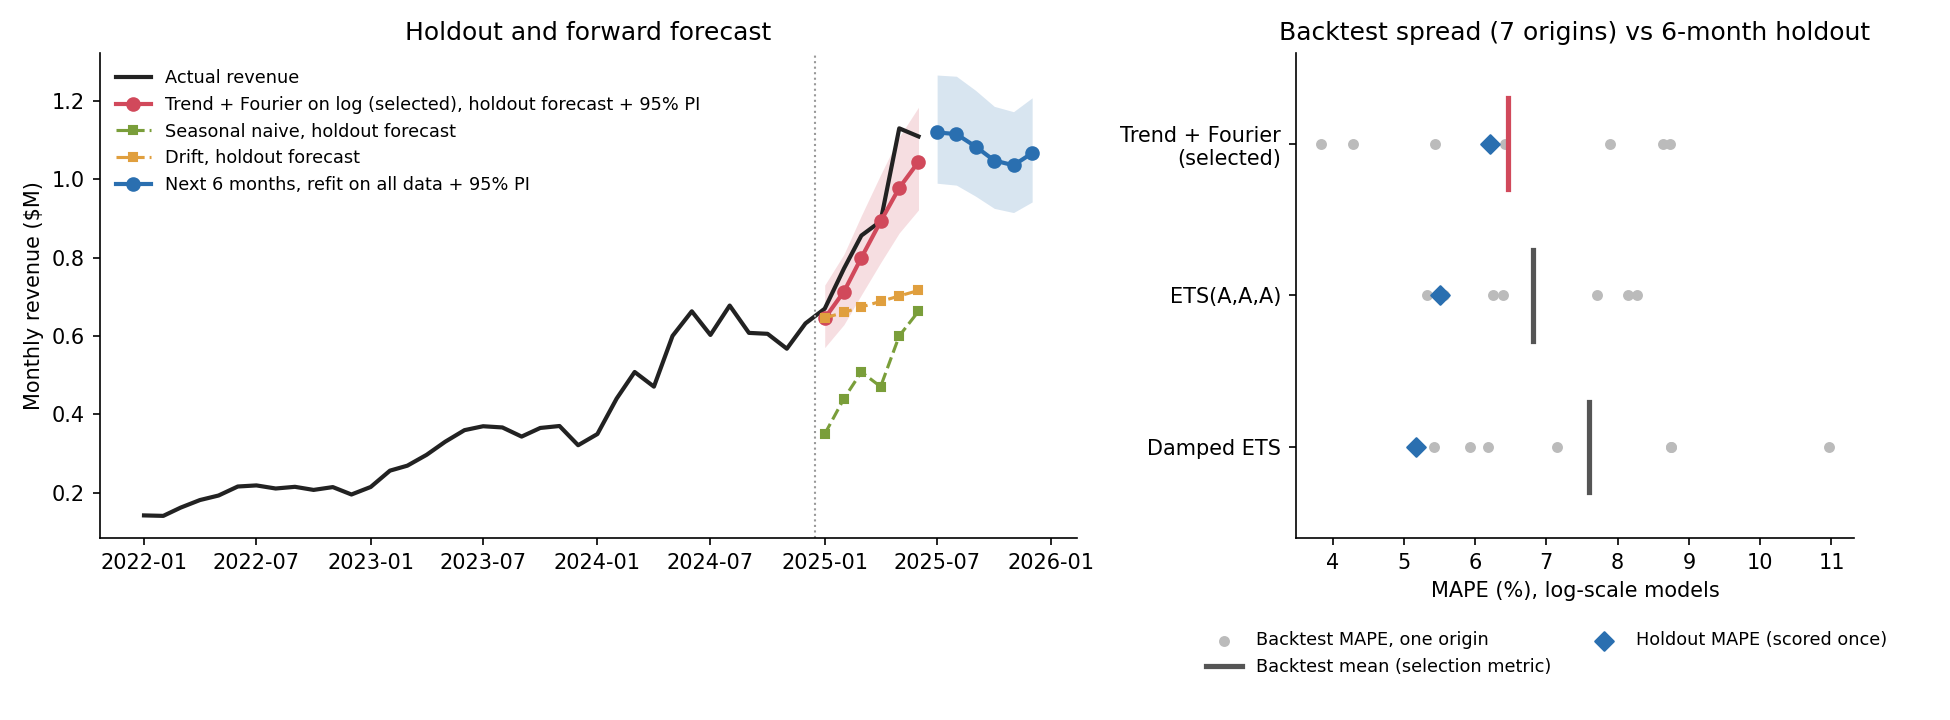

,month,forecast,lower_95,upper_95
0,2025-07,1.120e+06,990096.648,1.266e+06
1,2025-08,1.116e+06,985254.251,1.263e+06
2,2025-09,1.084e+06,956987.725,1.227e+06
3,2025-10,1.048e+06,925903.642,1.186e+06
4,2025-11,1.036e+06,915237.805,1.173e+06
5,2025-12,1.067e+06,942241.260,1.208e+06


In [9]:
print("Selected by backtest:", revenue["selected_method"])
display(pd.DataFrame(revenue["holdout"]).set_index("method"))
display(Image("figures/revenue_forecast.png"))
pd.read_csv("metrics/revenue_forward_forecast.csv")

## Takeaways

* A regularized logistic regression ranks churn risk about as well as the true model allows; flagging the top 10% of accounts finds churners at close to three times the base rate.
* Under the stated assumptions, working the model's top list protects roughly two to three times the revenue a random list of the same size would, and each extra block of outreach returns less than the one before.
* For revenue, modeling growth and seasonality on the log scale cuts holdout error from 23% MAPE (best baseline) to about 6%. The trend + Fourier model is selected on the backtest; the other log-scale models and the ensemble are within about one point of it on both backtest and holdout, which this much data can't resolve.
* The test period has 280 accounts and the revenue holdout six months, so the intervals around these numbers are wide.